In [57]:
%pip install soundfile
%pip install huggingface_hub
%pip install datasets
%pip install librosa 
%pip install torch
%pip install torchcodec
%pip install pedalboard

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 17.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [70]:
import soundfile as sf
import IPython
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import pickle
import sklearn
import torch
import torchcodec
from datasets import load_dataset
from datasets import Audio
from os.path import join
import os
from tqdm import tqdm
from pedalboard import Pedalboard, Distortion, Clipping, Bitcrush
from pedalboard.io import AudioFile

Unique sample rates: [44100]
Total number of recordings: 580

Minimum duration: 2.10 seconds
Maximum duration: 42.38 seconds
Mean duration: 15.55 seconds

Total 5-second clips: 1516


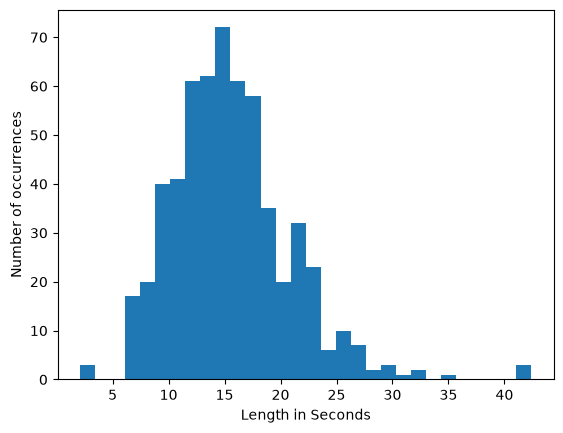

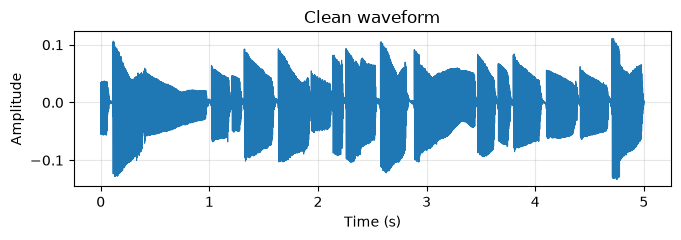

In [114]:
# This cell is for data loading and inspecting the dataset

# The dataset was already split into test train and val, but we want to do this ourselves
dataset_path = "guitar_jam"

train_files = glob(join(dataset_path, "train", "*.wav"))
test_files = glob(join(dataset_path, "test", "*.wav"))
val_files = glob(join(dataset_path, "val", "*.wav"))

# Combine all file paths into one list
combined_files = train_files + test_files + val_files

# Inspect sample rates 
sample_rates = []

for file_path in combined_files:
    info = sf.info(file_path)
    sample_rates.append(info.samplerate)

print("Unique sample rates:", np.unique(sample_rates))
print("Total number of recordings:", len(all_files))
print()

# Inspect duration of files

durations = []

for file_path in all_files:
    info = sf.info(file_path)
    durations.append(info.duration)

print(f"Minimum duration: {np.min(durations):.2f} seconds")
print(f"Maximum duration: {np.max(durations):.2f} seconds")
print(f"Mean duration: {np.mean(durations):.2f} seconds")
print()

plt.hist(durations, bins=30)
plt.xlabel('Length in Seconds')
plt.ylabel('Number of occurrences')

# Audio clips are of varied lengths so we should split to make them the same length

def audio_splitter(audio_array, sample_rate):

    samples_per_clip = int(sample_rate * 5)

    num_clips = len(audio_array) // samples_per_clip

    split_audio = []

    for i in range(num_clips):

        # Calculate starting and ending samples
        start = i * samples_per_clip
        end = start + samples_per_clip

        # Extract audio section
        clip = audio_array[start:end]

        split_audio.append(clip)

    return split_audio

dataset = []

for sample in combined_files:

    # Load audio
    audio_array, sr = sf.read(sample)

    # Split into 5-second clips
    clips = audio_splitter(audio_array, sr)
    
    filename = sample.split(os.sep)[2]


    i = 0

    for clip in clips:
        dataset.append({
            "audio": clip,
            "filename": filename,
            "clip_number": i
        })

        i += 1

print("Total 5-second clips:", len(dataset))  

# Calculate duration of every processed clip
clip_durations = []

for clip in dataset:
    duration = len(clip) / sr
    clip_durations.append(duration)

x = dataset[60]["audio"]
IPython.display.Audio(data = x, rate=sr)

def plot_waveform(audio, sr, title) :
    t = np.linspace(0, len(audio)/sr, num=len(audio))
    plt.figure(figsize=(7, 2.5))
    plt.plot(t, audio, linewidth=0.8)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(f"{title}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_waveform(x, sr, "Clean waveform")

Distorted audio


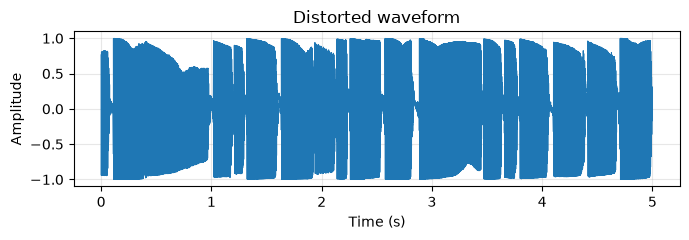

Clipped audio


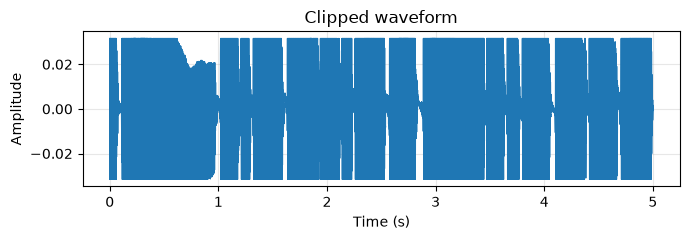

Bitcrushed audio


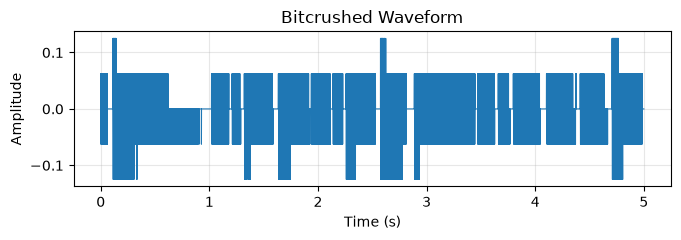

In [143]:
# Experimenting with different distortion techniques and how they effect waveform

# First effect is 'Distortion'
# From testing I would use drive as 30, 40 and 50 for light, medium, heavy distortion

distortion = Distortion(drive_db=30)

board = Pedalboard([
    distortion
])

distortion_audio = board(x, sr)
print("Distorted audio")
display(IPython.display.Audio(distortion_audio, rate=sr))

plot_waveform(distortion_audio, sr, "Distorted waveform")



# The second effect is 'Clipping'
# I would use the threshold as -30, -40, -50

clipping = Clipping(threshold_db=-30)

# Create an effects chain
board = Pedalboard([
    clipping
])

clipped_audio = board(x, sr)
print("Clipped audio")
display(IPython.display.Audio(data = clipped_audio, rate=sr))

plot_waveform(clipped_audio, sr, "Clipped waveform")





# The third effect is 'Bitcrushing'
# Bit crushing 

bitcrushing = Bitcrush(bit_depth=4)

board = Pedalboard([
    bitcrushing
])

bitcrushed_audio = board(x, sr)
print("Bitcrushed audio")
display(IPython.display.Audio(data = bitcrushed_audio, rate=sr))

plot_waveform(bitcrushed_audio, sr, "Bitcrushed Waveform")


In [144]:
# This cell is for splitting the data

In [53]:
# This cell will be for feature extraction, I only just started so needs work, see worksheet 8

# Define function to extract each feature using librosa

def extract_features(x, sr):
    x = np.asarray(x, dtype=np.float32)

    centroid = librosa.feature.spectral_centroid(y=x, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=x, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=x, sr=sr, roll_percent=0.85)
    flatness = librosa.feature.spectral_flatness(y=x)
    contrast = librosa.feature.spectral_contrast(y=x, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(y=x)
    rms = librosa.feature.rms(y=x)

    # Get mean of features
    features = [
        np.mean(centroid), np.std(centroid),
        np.mean(bandwidth), np.std(bandwidth),
        np.mean(rolloff), np.std(rolloff),
        np.mean(flatness), np.std(flatness),        
        np.mean(contrast), np.std(contrast),
        np.mean(zcr), np.std(zcr),
        np.mean(rms), np.std(rms),        
    ]

    return np.stack(features)
